# YOLOv8: Train and Segment Water Surfaces

This workshop trains a small YOLOv8 segmentation model for **3 epochs**, then uses the shared `YOLO/best.pt` for case1 and case2 predictions. Finish by drawing a polygon reference and calculating water fractions.

Participants do **not** need to download or copy the shared 7 GB of photos and models. Add the workshop folder as a shortcut under My Drive and share it with Viewer access. This notebook reads the dataset, images, YAML, code, and models from that shared folder. It saves preprocessing, training, masks, and plots to your personal `MyDrive/Workshop_Results/yolov8` folder.

## 1. Runtime and Installation

**Local:** select the `yolov8_workshop` Conda environment. It uses CUDA-enabled PyTorch and `ultralytics==8.3.233`, which supports the supplied YOLOv8x checkpoint.

**Colab:** select a GPU runtime and run the setup cell to install dependencies and mount Drive. Make sure the shared folder shortcut is named `Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery`, or change `PROJECT_ROOT` in the configuration cell. Do not copy the shared inputs. Outputs are written to your personal Drive. The training starter model is downloaded to Colab's temporary local storage, not to the read-only shared folder.

In [ ]:
import importlib.util
from importlib.metadata import PackageNotFoundError, version
import os
import sys

try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False


def installed_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None


required_packages = ('pandas', 'PyYAML', 'matplotlib', 'ipympl', 'ipywidgets')
widget_packages = ('ipympl', 'ipywidgets')
widget_versions_before = {package: installed_version(package) for package in widget_packages}
INSTALL_PACKAGES = IN_COLAB and (
    installed_version('ultralytics') != '8.3.233'
    or any(installed_version(package) is None for package in required_packages)
)
MOUNT_GOOGLE_DRIVE = IN_COLAB
os.environ['YOLO_AUTOINSTALL'] = 'false'
if INSTALL_PACKAGES:
    %pip install ultralytics==8.3.233 pandas pyyaml matplotlib
if IN_COLAB:
    %pip install --upgrade ipympl ipywidgets
widget_versions_after = {package: installed_version(package) for package in widget_packages}
if INSTALL_PACKAGES or widget_versions_before != widget_versions_after:
    raise RuntimeError(
        'Packages were installed or upgraded. Choose Runtime > Restart session, then rerun this cell. '
        'If no versions change on the next run, setup will continue without another restart. '
        'Do not train or run inference before this setup cell succeeds.'
    )

import matplotlib
from matplotlib.backends import backend_registry

if not backend_registry.is_valid_backend('module://ipympl.backend_nbagg'):
    raise RuntimeError(
        f'Matplotlib {matplotlib.__version__} has not registered ipympl '
        f'{installed_version("ipympl")}. Restart the session and rerun this cell first. '
        'If it still fails, report the matplotlib, ipympl, and ipywidgets versions '
        'before running training.'
    )
if 'ultralytics' in sys.modules and sys.modules['ultralytics'].__version__ != '8.3.233':
    raise RuntimeError('Restart the session to use the installed Ultralytics version.')
print('Plotting dependencies:', {package: installed_version(package)
                                 for package in ('matplotlib', 'ipympl', 'ipywidgets')})

if IN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
    if MOUNT_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')

Plotting dependencies: {'matplotlib': '3.10.0', 'ipympl': '0.10.0', 'ipywidgets': '8.1.9'}
Mounted at /content/drive


## 2. Paths and Configuration

Set `PROJECT_ROOT` to the directory containing the companion, YOLO folder, and example photos. `EPOCHS = 3` is the short training demonstration; The training architecture is YOLOv8n-seg, while `INFERENCE_CHECKPOINT` always points to the supplied YOLOv8x water model.

`CONFIDENCE` filters detected water instances. `IOU_THRESHOLD` controls overlap suppression between detections; it is not the final water-fraction metric. `WATER_CLASS_ID = 0` is `surfwater` in the supplied checkpoint.

All new model/analysis outputs are under `workshop_outputs/yolov8`. Case1 preprocessing still writes to `example_photos/case1/preprocess`.

In [ ]:
from pathlib import Path
import hashlib
import json
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics
from ultralytics import YOLO
from IPython.display import display

PROJECT_ROOT = (Path('/content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery')
                if IN_COLAB else Path.cwd())
PERSONAL_OUTPUT_ROOT = (
    Path('/content/drive/MyDrive/Workshop_Results')
    if IN_COLAB else PROJECT_ROOT / 'workshop_outputs'
)
assert (PROJECT_ROOT / 'water_surface_workshop.py').is_file(), 'Set PROJECT_ROOT to the shared workshop folder.'
sys.path.insert(0, str(PROJECT_ROOT))
from water_surface_workshop import (
    image_paths, load_rgb, preprocess_case1, overlay_mask, timestamp_from_name,
    largest_water_mask, row_fractions, calculate_time_series, plot_time_series,
)

assert ultralytics.__version__ == '8.3.233', 'Use the pinned environment; restart the runtime after installing packages.'
DATASET_ROOT = PROJECT_ROOT / 'example_photos' / 'wlc_YOLODataset_380pic'
CASE1 = PROJECT_ROOT / 'example_photos' / 'case1'
OUTPUT = PERSONAL_OUTPUT_ROOT / 'yolov8'
PREPROCESSED = OUTPUT / 'case1' / 'preprocess'
CASE2 = PROJECT_ROOT / 'example_photos' / 'case2'
CASE2_OUTPUT = OUTPUT / 'case2'
POLYGON_OUTPUT = OUTPUT / 'case2_polygon'
INFERENCE_CHECKPOINT = PROJECT_ROOT / 'YOLO' / 'best.pt'
TRAINING_START_WEIGHTS = PROJECT_ROOT / 'YOLO' / 'yolov8n-seg.pt'
if IN_COLAB and not TRAINING_START_WEIGHTS.is_file():
    TRAINING_START_WEIGHTS = Path('/content/yolov8n-seg.pt')
DATA_YAML = PROJECT_ROOT / 'YOLO' / 'config_wlc_380pic.yaml'
EPOCHS = 3
TRAIN_BATCH = 4
IMAGE_SIZE = 640
WATER_CLASS_ID = 0
CONFIDENCE = 0.25
IOU_THRESHOLD = 0.7
CHANNEL_TOLERANCE = 10
GRAYSCALE_CUTOFF = 0.98
WIDTH = 640
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print('Shared inputs:', PROJECT_ROOT)
print('Personal outputs:', OUTPUT)
print('Training starter weights:', TRAINING_START_WEIGHTS)
print('Python:', sys.version.split()[0], '| Ultralytics:', ultralytics.__version__, '| Torch:', torch.__version__)
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU: training will be slow')
print('Case1:', len(image_paths(CASE1)), '| Case2:', len(image_paths(CASE2)))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Shared inputs: /content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery
Personal outputs: /content/drive/MyDrive/Workshop_Results/yolov8
Training starter weights: /content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery/YOLO/yolov8n-seg.pt
Python: 3.13.16 | Ultralytics: 8.3.233 | Torch: 2.11.0+cu130
Device: Tesla T4
Case1: 3 | Case2: 64


## 3. Train a Small YOLOv8 Model for Three Epochs

This demonstration fine-tunes COCO-pretrained **YOLOv8n-seg**, not the supplied water checkpoint. Three epochs demonstrate the training process; they do not produce a converged model.

Training reads the YAML, images, labels, and available starter weights directly from the shared, read-only Drive folder. If `YOLO/yolov8n-seg.pt` is missing, it downloads that small starter model to Colab's temporary local storage, not to the shared folder. Training uses the existing 304/76 split and 640-pixel images.

Training logs, demo weights, and all later outputs go to your personal `Workshop_Results/yolov8` folder. Reduce batch 4 if GPU memory is insufficient. Shared dataset files may report that a label cache could not be saved; training can proceed without caching.

In [ ]:
from ultralytics import settings as yolo_settings
from ultralytics.utils.downloads import attempt_download_asset

yolo_settings.update({'wandb': False, 'mlflow': False, 'comet': False,
                      'clearml': False, 'neptune': False, 'dvc': False, 'tensorboard': False})
if not 3 <= EPOCHS <= 5:
    raise ValueError('Keep this workshop demo to 3–5 epochs; change the guard deliberately for a longer experiment.')
assert INFERENCE_CHECKPOINT.is_file(), f'Missing supplied best.pt: {INFERENCE_CHECKPOINT}'
checkpoint_hash_before = hashlib.sha256(INFERENCE_CHECKPOINT.read_bytes()).hexdigest()
if not TRAINING_START_WEIGHTS.is_file():
    attempt_download_asset(str(TRAINING_START_WEIGHTS))
training_model = YOLO(str(TRAINING_START_WEIGHTS))
training_results = training_model.train(
    data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE,
    batch=TRAIN_BATCH, device=DEVICE, workers=0, cache=False,
    seed=42, deterministic=True, amp=True, patience=EPOCHS + 1,
    close_mosaic=0, project=str(OUTPUT / 'training'), name='demo_yolov8n',
    exist_ok=False, plots=True, verbose=False,
)
training_directory = Path(training_model.trainer.save_dir)
display(pd.read_csv(training_directory / 'results.csv'))
print('Demo checkpoint:', training_directory / 'weights' / 'best.pt')
assert hashlib.sha256(INFERENCE_CHECKPOINT.read_bytes()).hexdigest() == checkpoint_hash_before
print('Supplied inference checkpoint is unchanged:', INFERENCE_CHECKPOINT)
del training_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.233 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery/YOLO/config_wlc_380pic.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/driv

,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),...,metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,67.8062,2.04825,4.51508,2.55961,1.72296,0.34205,0.16554,0.13526,0.06214,...,0.15266,0.12063,0.03902,1.90181,4.26032,2.57363,1.84964,0.000658,0.000658,0.000658
1,2,87.7129,1.91028,3.66450,2.09997,1.60879,0.59729,0.25676,0.34494,0.17343,...,0.26009,0.28995,0.11048,1.65886,3.42450,2.27217,1.60556,0.000887,0.000887,0.000887
2,3,109.7090,1.82653,3.43185,1.94615,1.50542,0.56361,0.31081,0.37228,0.16645,...,0.31757,0.34394,0.13863,1.79388,3.04228,2.11134,1.81021,0.000677,0.000677,0.000677


Demo checkpoint: /content/drive/MyDrive/Workshop_Results/yolov8/training/demo_yolov8n/weights/best.pt
Supplied inference checkpoint is unchanged: /content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery/YOLO/best.pt


## 4. Case1: Filter Night Vision, Resize, and Inspect

For each RGB pixel, calculate `max(R,G,B) - min(R,G,B)`. A pixel is nearly gray when this difference is at most `CHANNEL_TOLERANCE = 10`. Reject a photo if at least `GRAYSCALE_CUTOFF = 0.98` of pixels are nearly gray.

Retained photos are resized to width 640 and written to your personal `Workshop_Results/yolov8/case1/preprocess` folder. Shared originals are read-only and are not changed.

,filename,grayscale_fraction,status,original_width,original_height,output_width,output_height,output_path
0,RMP_S30R_20230718_001346PST-5.JPG,1.000000,night_vision,9040,5072,NaN,NaN,
1,RMP_S30R_20230718_041346PST-1.JPG,0.591411,kept,9040,5072,640.0,359.0,/content/drive/MyDrive/Workshop_Results/yolov8...
2,RMP_S30R_20231021_170820PST-3.JPG,0.194921,kept,9040,5072,640.0,359.0,/content/drive/MyDrive/Workshop_Results/yolov8...


status
kept            2
night_vision    1


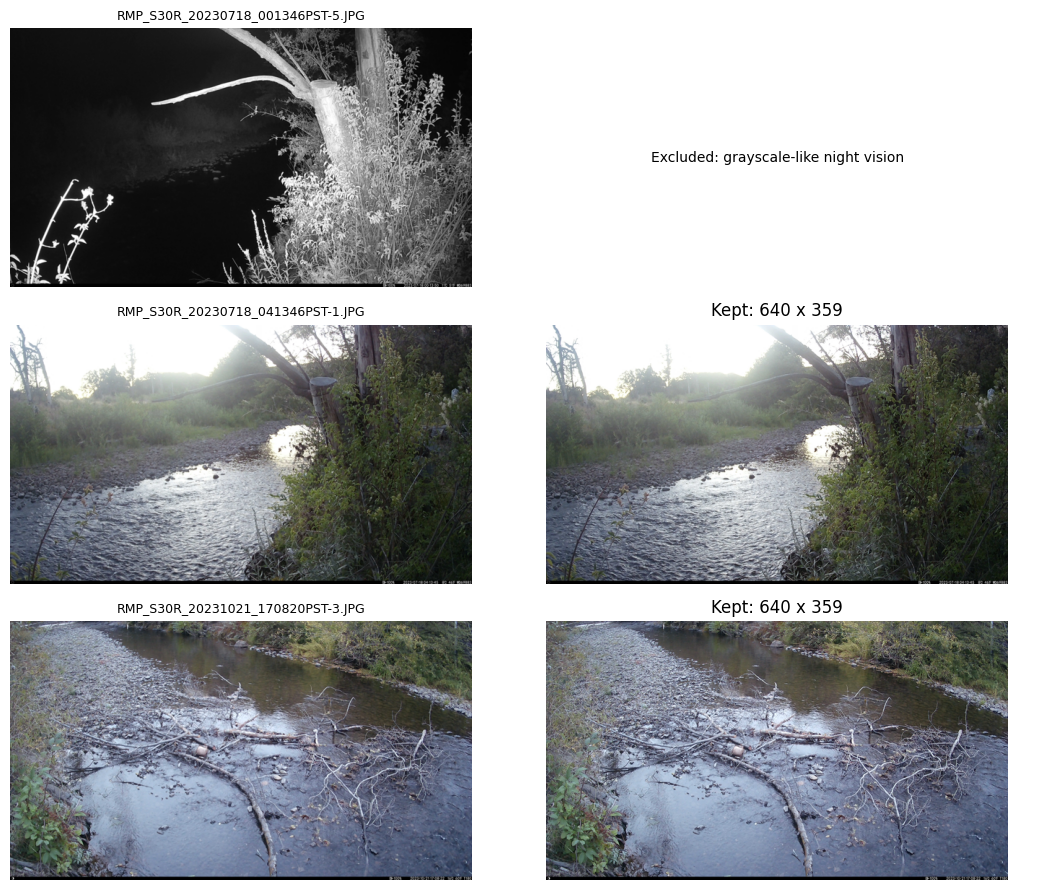

In [ ]:
preprocess_report = preprocess_case1(
    CASE1, WIDTH, CHANNEL_TOLERANCE, GRAYSCALE_CUTOFF, output_dir=PREPROCESSED
)
display(preprocess_report)
print(preprocess_report['status'].value_counts().to_string())

figure, axes = plt.subplots(len(preprocess_report), 2,
                            figsize=(11, 3 * len(preprocess_report)), squeeze=False)
for row_number, record in enumerate(preprocess_report.to_dict('records')):
    original = load_rgb(CASE1 / record['filename'])
    original.thumbnail((640, 640))
    axes[row_number, 0].imshow(original)
    axes[row_number, 0].set_title(record['filename'], fontsize=9)
    if record['status'] == 'kept':
        resized = load_rgb(record['output_path'])
        assert resized.width == WIDTH
        axes[row_number, 1].imshow(resized)
        axes[row_number, 1].set_title(f'Kept: {resized.width} x {resized.height}')
    else:
        axes[row_number, 1].text(0.5, 0.5, 'Excluded: grayscale-like night vision',
                                 ha='center', va='center', wrap=True)
    for axis in axes[row_number]:
        axis.axis('off')
figure.tight_layout()
plt.show()

## 5. Load the Shared Water Checkpoint and Infer Case1

Loads `YOLO/best.pt` read-only from the shared Drive folder. Masks, overlays, and the summary CSV are written to your personal `Workshop_Results/yolov8/case1` folder.

Inference uses the supplied checkpoint, not the 3-epoch demo: /content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery/YOLO/best.pt
Classes: {0: 'surfwater'}
[1/2] RMP_S30R_20230718_041346PST-1.JPG.png: 0.2311
[2/2] RMP_S30R_20231021_170820PST-3.JPG.png: 0.4596


,filename,water_fraction,detection_status
0,RMP_S30R_20230718_041346PST-1.JPG.png,0.231137,water
1,RMP_S30R_20231021_170820PST-3.JPG.png,0.459623,water


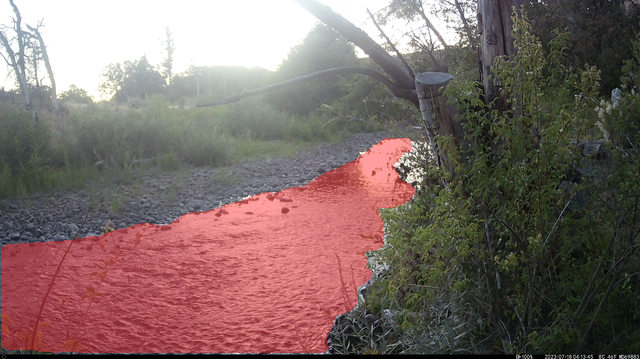

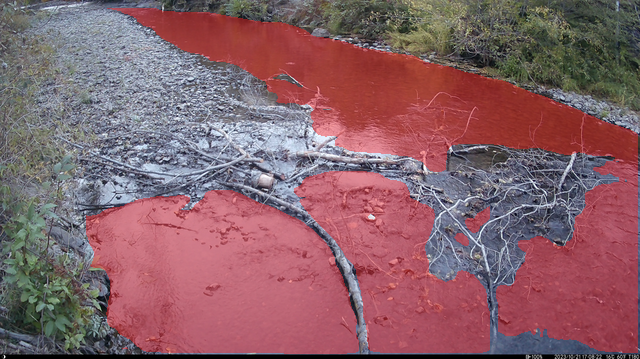

In [ ]:
def yolo_water_mask(image, model, device, confidence=0.25, iou=0.7, class_id=0):
    result = model.predict(source=image, imgsz=640, conf=confidence, iou=iou,
                           classes=[class_id], retina_masks=True,
                           device=device, verbose=False)[0]
    combined = np.zeros((image.height, image.width), dtype=bool)
    if result.masks is None:
        return combined
    masks = result.masks.data.detach().cpu().numpy()
    classes = result.boxes.cls.detach().cpu().numpy().astype(int)
    if masks.shape[1:] != combined.shape:
        raise ValueError(f'Native mask shape {masks.shape[1:]} differs from image {combined.shape}.')
    return np.any(masks[classes == class_id] > 0, axis=0)


def segment_yolo_folder(folder, output, model):
    paths = image_paths(folder)
    output = Path(output)
    for name in ('masks', 'overlays'):
        (output / name).mkdir(parents=True, exist_ok=True)
    records = []
    for number, path in enumerate(paths, start=1):
        image = load_rgb(path)
        if image.width != 640:
            raise ValueError(f'{path.name}: expected width 640, got {image.width}')
        mask = yolo_water_mask(image, model, DEVICE, CONFIDENCE, IOU_THRESHOLD, WATER_CLASS_ID)
        mask_path = output / 'masks' / f'{path.name}.npy'
        np.save(mask_path, mask)
        overlay_mask(image, mask).save(output / 'overlays' / f'{path.name}.png')
        records.append(dict(filename=path.name, image_path=str(path),
                            timestamp=timestamp_from_name(path.name),
                            mask_path=str(mask_path), water_pixels=int(mask.sum()),
                            image_pixels=mask.size, water_fraction=float(mask.mean()),
                            detection_status='water' if mask.any() else 'no_detection',
                            inference_checkpoint=str(INFERENCE_CHECKPOINT)))
        print(f'[{number}/{len(paths)}] {path.name}: {mask.mean():.4f}', flush=True)
    table = pd.DataFrame(records)
    table.to_csv(output / 'segmentation_summary.csv', index=False)
    return table


assert INFERENCE_CHECKPOINT.is_file(), f'Missing supplied checkpoint: {INFERENCE_CHECKPOINT}'
model = YOLO(str(INFERENCE_CHECKPOINT))
assert model.task == 'segment', f'Expected segmentation checkpoint, got {model.task}'
assert model.names.get(WATER_CLASS_ID) == 'surfwater', model.names
print('Inference uses the supplied checkpoint, not the 3-epoch demo:', INFERENCE_CHECKPOINT)
print('Classes:', model.names)
case1_table = segment_yolo_folder(PREPROCESSED, OUTPUT / 'case1', model)
display(case1_table[['filename', 'water_fraction', 'detection_status']])
for record in case1_table.to_dict('records'):
    display(overlay_mask(load_rgb(record['image_path']),
                         np.load(record['mask_path'], allow_pickle=False)))

## 6. Segment Case2 and Select the Largest Water Mask

Case2 is already 640 wide. All photos must have identical dimensions for row-by-row comparison. The cell processes every current image in the folder, records camera timestamps, and saves binary masks, overlays, and a summary CSV.

For each photo, the whole-image water fraction is

$$f_i = \frac{\text{water-mask pixels in photo }i}{H_i W_i}.$$

The image with the largest fraction supplies the visual guide for polygon drawing.

[1/64] RMP_S32_20231001_090002PST-1.png: 0.2413
[2/64] RMP_S32_20231001_090002PST-2.png: 0.2425
[3/64] RMP_S32_20231001_090002PST-3.png: 0.2418
[4/64] RMP_S32_20231001_090002PST-4.png: 0.2446
[5/64] RMP_S32_20231001_090002PST-5.png: 0.2442
[6/64] RMP_S32_20231001_110002PST-1.png: 0.2346
[7/64] RMP_S32_20231001_110002PST-2.png: 0.2318
[8/64] RMP_S32_20231001_110002PST-3.png: 0.2330
[9/64] RMP_S32_20231001_110002PST-4.png: 0.2341
[10/64] RMP_S32_20231001_110002PST-5.png: 0.2328
[11/64] RMP_S32_20231001_150002PST-1.png: 0.2284
[12/64] RMP_S32_20231001_150002PST-2.png: 0.2275
[13/64] RMP_S32_20231001_150002PST-3.png: 0.2298
[14/64] RMP_S32_20231001_150002PST-4.png: 0.2198
[15/64] RMP_S32_20231001_150002PST-5.png: 0.2245
[16/64] RMP_S32_20231001_170002PST-1.png: 0.2007
[17/64] RMP_S32_20231001_170002PST-2.png: 0.1999
[18/64] RMP_S32_20231001_170002PST-3.png: 0.2053
[19/64] RMP_S32_20231001_170002PST-4.png: 0.2021
[20/64] RMP_S32_20231001_170002PST-5.png: 0.2055
[21/64] RMP_S32_20231002_0700

,filename,image_path,timestamp,mask_path,water_pixels,image_pixels,water_fraction,detection_status,inference_checkpoint
0,RMP_S32_20231001_090002PST-1.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/yolov8...,55437,229760,0.241282,water,"/content/drive/MyDrive/Part 1, Module 2: Surfa..."
1,RMP_S32_20231001_090002PST-2.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/yolov8...,55724,229760,0.242531,water,"/content/drive/MyDrive/Part 1, Module 2: Surfa..."
2,RMP_S32_20231001_090002PST-3.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/yolov8...,55552,229760,0.241783,water,"/content/drive/MyDrive/Part 1, Module 2: Surfa..."
3,RMP_S32_20231001_090002PST-4.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/yolov8...,56190,229760,0.244560,water,"/content/drive/MyDrive/Part 1, Module 2: Surfa..."
4,RMP_S32_20231001_090002PST-5.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/yolov8...,56097,229760,0.244155,water,"/content/drive/MyDrive/Part 1, Module 2: Surfa..."


detection_status
water    64
Largest: RMP_S32_20231001_090002PST-4.png | water area fraction: 0.24455954038997216


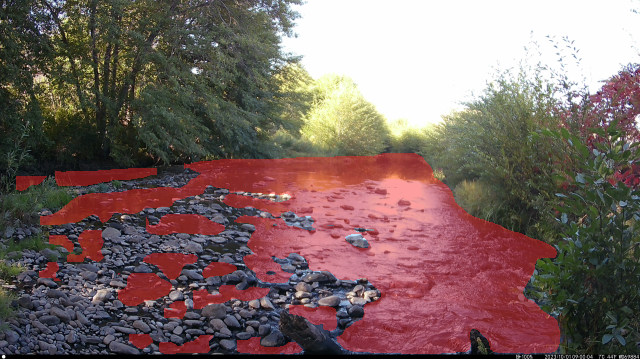

In [ ]:
case2_paths = image_paths(CASE2)
case2_sizes = {load_rgb(path).size for path in case2_paths}
assert len(case2_sizes) == 1, f'Case2 images must share one shape: {case2_sizes}'
assert next(iter(case2_sizes))[0] == WIDTH == 640
case2_table = segment_yolo_folder(CASE2, CASE2_OUTPUT, model)
display(case2_table.head())
print(case2_table['detection_status'].value_counts().to_string())
largest_record, largest_mask = largest_water_mask(case2_table)
np.save(CASE2_OUTPUT / 'largest_original_mask.npy', largest_mask)
print('Largest:', largest_record['filename'], '| water area fraction:', largest_record['water_fraction'])
largest_image = load_rgb(largest_record['image_path'])
display(overlay_mask(largest_image, largest_mask))

## 7. Draw the Polygon Reference and Calculate Row Fractions

The largest original YOLOv8 water mask is a visual guide only. Draw your desired maximum water-surface region over its photo. The polygon's filled interior and boundary define the reference.

For each photo's mask $M_i$ and your polygon mask $R$:

$$q_{i,r}=\frac{|M_{i,r}\cap R_r|}{|R_r|},\qquad Q_i=\frac{1}{|V|}\sum_{r\in V}q_{i,r},\qquad V=\{r:|R_r|>0\}.$$

Every row containing reference pixels receives equal weight; rows outside the polygon are excluded. This is not a ratio of total areas. Water outside the polygon is ignored, and values stay between 0 and 1.

In [ ]:
def polygon_to_mask(vertices, shape):
    from PIL import Image, ImageDraw

    points = np.asarray(vertices, dtype=float)
    if points.ndim != 2 or points.shape[1] != 2 or len(points) < 3:
        raise ValueError('Draw a polygon with at least three vertices.')
    if not np.isfinite(points).all() or len(np.unique(points, axis=0)) < 3:
        raise ValueError('Polygon vertices must be finite and distinct.')
    height, width = shape
    if ((points[:, 0] < 0).any() or (points[:, 0] > width - 1).any()
            or (points[:, 1] < 0).any() or (points[:, 1] > height - 1).any()):
        raise ValueError('Keep all polygon vertices inside the image.')
    area = abs(np.dot(points[:, 0], np.roll(points[:, 1], 1))
               - np.dot(points[:, 1], np.roll(points[:, 0], 1))) / 2
    if area < 1:
        raise ValueError('Draw a nondegenerate polygon with an area of at least one pixel.')
    canvas = Image.new('L', (width, height), 0)
    ImageDraw.Draw(canvas).polygon([tuple(point) for point in points], fill=1)
    mask = np.asarray(canvas, dtype=bool)
    if not mask.any():
        raise ValueError('The polygon reference is empty.')
    return mask


def run_analysis(vertices):
    from IPython.display import Image as NotebookImage
    from matplotlib.patches import Patch, Polygon

    reference = polygon_to_mask(vertices, largest_mask.shape)
    POLYGON_OUTPUT.mkdir(parents=True, exist_ok=True)
    photos, times, rows = calculate_time_series(case2_table, reference, POLYGON_OUTPUT)
    photos = photos.drop(columns=['expansion_pixels'])
    photos.to_csv(POLYGON_OUTPUT / 'photo_fractions.csv', index=False)
    np.save(POLYGON_OUTPUT / 'largest_original_mask.npy', largest_mask)
    with plt.ioff():
        figure, axis = plt.subplots(figsize=(10, 5))
        axis.imshow(overlay_mask(largest_image, reference, color=(0, 210, 210)))
        axis.add_patch(Polygon(vertices, closed=True, fill=False, edgecolor='cyan', linewidth=2))
        axis.set_title('User-drawn polygon reference')
        axis.legend(handles=[Patch(facecolor='cyan', label='Polygon reference')], loc='lower right')
        axis.axis('off')
        figure.tight_layout()
        figure.savefig(POLYGON_OUTPUT / 'reference_polygon.png', dpi=180)
        display(NotebookImage(filename=str(POLYGON_OUTPUT / 'reference_polygon.png')))
        plt.close(figure)
        figure = plot_time_series(photos, times, POLYGON_OUTPUT)
        display(NotebookImage(filename=str(POLYGON_OUTPUT / 'water_fraction_vs_time.png')))
        plt.close(figure)
        figure, axis = plt.subplots(figsize=(12, 3))
        axis.scatter(photos['timestamp'], photos['water_fraction'], s=10, alpha=0.4)
        axis.set(xlabel='Camera time (PST label)', ylabel='Water / whole image', ylim=(0, 1))
        figure.autofmt_xdate()
        figure.tight_layout()
        figure.savefig(POLYGON_OUTPUT / 'water_area_fraction_vs_time.png', dpi=180)
        display(NotebookImage(filename=str(POLYGON_OUTPUT / 'water_area_fraction_vs_time.png')))
        plt.close(figure)
    polygon_data = {
        'vertices_xy': np.asarray(vertices, dtype=float).tolist(),
        'image_shape': list(reference.shape),
        'source_image': str(largest_record['filename']),
        'coordinate_system': '640-wide image pixels; x rightward, y downward, origin at top left',
        'rasterization': 'Pillow ImageDraw polygon; filled interior and boundary',
    }
    (POLYGON_OUTPUT / 'polygon_reference.json').write_text(json.dumps(polygon_data, indent=2), encoding='utf-8')
    metadata = {
        'model_family': 'YOLOv8 instance segmentation',
        'inference_checkpoint': str(INFERENCE_CHECKPOINT),
        'inference_checkpoint_sha256': hashlib.sha256(INFERENCE_CHECKPOINT.read_bytes()).hexdigest(),
        'demo_training_used_for_inference': False,
        'confidence_threshold': CONFIDENCE,
        'nms_iou_threshold': IOU_THRESHOLD,
        'water_class_id': WATER_CLASS_ID,
        'retina_masks': True,
        'channel_tolerance': CHANNEL_TOLERANCE,
        'grayscale_cutoff': GRAYSCALE_CUTOFF,
        'largest_source': str(largest_record['filename']),
        'largest_area_fraction': float(largest_record['water_fraction']),
        'reference_type': 'user_polygon',
        'reference_shape': list(reference.shape),
        'reference_pixels': int(reference.sum()),
        'reference_rows': int(reference.any(axis=1).sum()),
        'photo_count': len(photos),
        'timestamp_count': len(times),
        'torch': torch.__version__,
        'ultralytics': ultralytics.__version__,
        'seed': 42,
        'metric': 'mean over nonempty polygon rows of water intersection / polygon pixels',
        'timestamp_basis': 'filename camera-local PST label; no timezone conversion',
    }
    (POLYGON_OUTPUT / 'analysis_settings.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    display(photos[['filename', 'timestamp', 'water_fraction', 'mean_row_fraction']].head())
    print('Saved polygon analysis to', POLYGON_OUTPUT)
    return photos, times, reference

### 8. Draw and Apply the Reference

Run the next cell to display the interactive photo. Red marks the largest YOLOv8 water mask. Click consecutive vertices around the desired reference region, then click the first vertex to close the polygon. Stay inside the image and draw a simple, non-crossing outline. Cyan shading previews the filled reference.

Drag the completed polygon handles to adjust it. Click Apply and save to compute all photo fractions and export the polygon, settings, and plots. Editing alone does not overwrite saved results. Clear polygon starts a new outline without deleting previous files.

HTML(value='Draw a polygon, then close it by clicking its first vertex.')

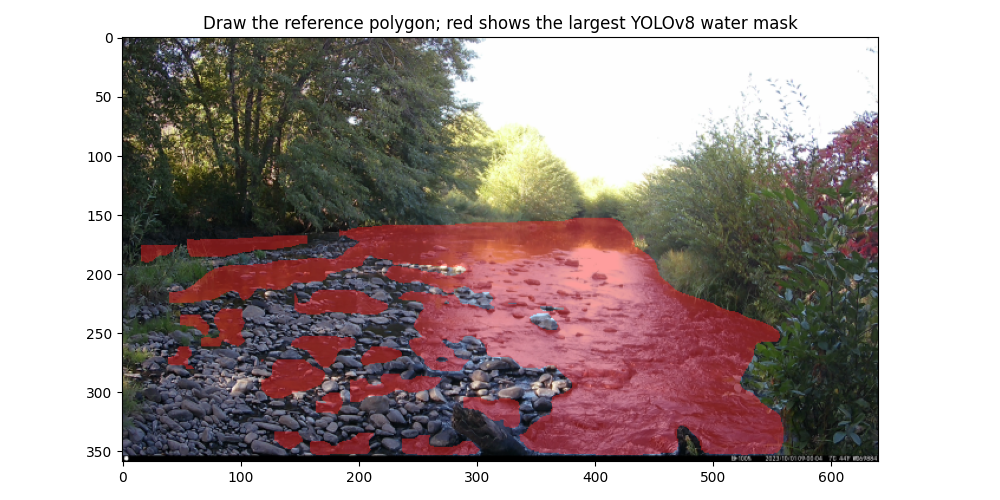

Output()

In [ ]:
import ipywidgets as widgets

if IN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
%matplotlib widget

import matplotlib.pyplot as plt
from matplotlib.widgets import PolygonSelector

polygon_vertices = []
pending_reference_mask = None
reference_mask = None
polygon_analysis_saved = False
apply_button = widgets.Button(description='Apply and save', icon='save', disabled=True)
reset_button = widgets.Button(description='Clear polygon', icon='eraser')
status = widgets.HTML(value='Draw a polygon, then close it by clicking its first vertex.')
analysis_output = widgets.Output()

with plt.ioff():
    drawing_figure, drawing_axis = plt.subplots(figsize=(10, 5))
drawing_axis.imshow(overlay_mask(largest_image, largest_mask))
polygon_overlay = np.zeros((*largest_mask.shape, 4), dtype=np.uint8)
reference_artist = drawing_axis.imshow(polygon_overlay)
drawing_axis.set_title('Draw the reference polygon; red shows the largest YOLOv8 water mask')
drawing_axis.set_xlim(-0.5, largest_image.width - 0.5)
drawing_axis.set_ylim(largest_image.height - 0.5, -0.5)
drawing_axis.set_aspect('equal')
drawing_figure.tight_layout()
drawing_figure.canvas.toolbar_visible = False


def select_reference(vertices):
    global polygon_vertices, pending_reference_mask, polygon_analysis_saved
    polygon_analysis_saved = False
    apply_button.disabled = True
    try:
        pending_reference_mask = polygon_to_mask(vertices, largest_mask.shape)
    except ValueError as error:
        pending_reference_mask = None
        polygon_vertices = []
        status.value = str(error)
        return
    polygon_vertices = np.asarray(vertices, dtype=float).tolist()
    polygon_overlay[:] = 0
    polygon_overlay[pending_reference_mask] = (0, 210, 210, 95)
    reference_artist.set_data(polygon_overlay)
    drawing_figure.canvas.draw_idle()
    apply_button.disabled = False
    status.value = (f'Polygon ready: {len(polygon_vertices)} vertices, '
                    f'{int(pending_reference_mask.sum())} reference pixels. Click Apply and save.')


polygon_selector = PolygonSelector(drawing_axis, select_reference,
                                   props={'color': 'cyan', 'linewidth': 2},
                                   handle_props={'markerfacecolor': 'cyan'})


def clear_polygon(button):
    global polygon_vertices, pending_reference_mask, polygon_analysis_saved
    polygon_selector.clear()
    polygon_vertices = []
    pending_reference_mask = None
    polygon_analysis_saved = False
    polygon_overlay[:] = 0
    reference_artist.set_data(polygon_overlay)
    drawing_figure.canvas.draw_idle()
    apply_button.disabled = True
    status.value = 'Draw a new polygon. Previous saved files are unchanged until Apply and save.'


def apply_polygon(button):
    global photo_fractions, timestamp_fractions, reference_mask, polygon_analysis_saved
    apply_button.disabled = True
    with analysis_output:
        analysis_output.clear_output(wait=True)
        try:
            photo_fractions, timestamp_fractions, reference_mask = run_analysis(polygon_vertices)
        except Exception:
            polygon_analysis_saved = False
            status.value = 'Analysis failed; inspect the error below. No successful result is being claimed.'
            raise
        else:
            polygon_analysis_saved = True
            status.value = f'Polygon analysis saved to {POLYGON_OUTPUT}.'
        finally:
            apply_button.disabled = pending_reference_mask is None


apply_button.on_click(apply_polygon)
reset_button.on_click(clear_polygon)
display(status)
display(drawing_figure.canvas)
display(widgets.HBox([reset_button, apply_button]))
display(analysis_output)
drawing_figure.canvas.draw()

## 9. Outputs

All generated files go to your personal Drive, under `MyDrive/Workshop_Results/yolov8`:

- `training/`: demo training logs and weights.
- `case1/`: preprocessed case1 images, masks, overlays, and summary.
- `case2/`: masks, overlays, and summary.
- `case2_polygon/`: polygon reference, fractions, and plots.

The shared folder is read-only and no participant copies or uploads the 7 GB of inputs. Case1 preprocessing, training outputs, segmentation products, and polygon results all stay in the participant's personal `Workshop_Results` folder.

In [ ]:
if not polygon_analysis_saved:
    print('Draw a polygon and click Apply and save before validating or downloading results.')
else:
    required_outputs = ['largest_original_mask.npy', 'reference_mask.npy',
                        'polygon_reference.json', 'reference_polygon.png',
                        'photo_fractions.csv', 'row_fractions.csv',
                        'timestamp_fractions.csv', 'water_fraction_vs_time.png',
                        'water_area_fraction_vs_time.png', 'analysis_settings.json']
    assert all((POLYGON_OUTPUT / name).is_file() for name in required_outputs)
    assert len(photo_fractions) == len(case2_paths)
    assert photo_fractions['mean_row_fraction'].between(0, 1).all()
    assert reference_mask.shape == largest_mask.shape
    print('Complete:', len(photo_fractions), 'photos;', len(timestamp_fractions), 'timestamps')
    display(timestamp_fractions.head())

Complete: 64 photos; 13 timestamps


,timestamp,mean_row_fraction,photo_count
0,2023-10-01 09:00:02,0.482454,5
1,2023-10-01 11:00:02,0.461494,5
2,2023-10-01 15:00:02,0.458452,5
3,2023-10-01 17:00:02,0.403738,5
4,2023-10-02 07:00:02,0.459348,5
